In [2]:
import numpy as np

In [5]:
data = np.load('../local/2026-02-11-full-dumps/beam_prefix_w20.npz')

In [7]:
import numpy as np

with np.load('../local/2026-02-11-full-dumps/beam_prefix_w20.npz') as data:
    for key in data.files:
        arr = data[key]
        print(f"Key: {key}")
        print(f"  Shape: {arr.shape}")
        print(f"  Dtype: {arr.dtype}")
        # Print a small sample (first few elements depending on dimensions)
        if arr.ndim == 0:
            print(f"  Value: {arr.item()}")
        elif arr.ndim == 1:
            print(f"  Sample: {arr[:5]}")
        else:
            print(f"  Sample shape slice: {arr[0] if len(arr) > 0 else 'empty'}")
        print("-" * 40)

Key: rows
  Shape: (98304,)
  Dtype: int64
  Sample: [0 1 2 3 4]
----------------------------------------
Key: rank
  Shape: (98304,)
  Dtype: int64
  Sample: [21 21 21 21  4]
----------------------------------------
Key: targets
  Shape: (98304,)
  Dtype: int64
  Sample: [2370440   58867  848058  329627 3733057]
----------------------------------------
Key: covered0
  Shape: (98304,)
  Dtype: bool
  Sample: [False  True  True  True  True]
----------------------------------------
Key: tuples
  Shape: (98304, 20, 2)
  Dtype: int32
  Sample shape slice: [[2453 2029]
 [3700 6255]
 [6024 2883]
 [1063 3536]
 [1063 3305]
 [1857 1274]
 [ 460 3952]
 [1201 7752]
 [ 460 3305]
 [ 460 2449]
 [6077 5583]
 [6024 1109]
 [ 460 2818]
 [2992 7674]
 [2954 1784]
 [1857 7397]
 [ 460 2925]
 [8009 3822]
 [ 460 8071]
 [1063 7203]]
----------------------------------------
Key: beam_width
  Shape: ()
  Dtype: int64
  Value: 20
----------------------------------------
Key: sid_sizes
  Shape: (2,)
  Dtype: int64


In [8]:
import numpy as np

# N_r = number of catalogue items one TIGER v2 search actually puts in front of
# the user: the sum of the sizes of the 20 SID tuples the beam returned.
DUMP    = '../local/2026-02-11-full-dumps/beam_prefix_w20.npz'
CATALOG = '../local/2026-27-10-1-pre/digr_data/catalog_sid_codes.npy'

with np.load(DUMP) as d:
    tuples = d['tuples'].astype(np.int64)     # [rows, width, levels]
    sizes  = d['sid_sizes'].astype(np.int64)  # [8192, 8192]

cat = np.load(CATALOG, mmap_mode='r')         # [items, levels]

# Mixed radix: the same integer-per-tuple map budget_match.py packs with.
radix = np.array([int(np.prod(sizes[i + 1:])) for i in range(sizes.size)])
pack = lambda codes: (codes * radix).sum(-1)

cat_keys = pack(cat)
uniq, items_per_tuple = np.unique(cat_keys, return_counts=True)
assert cat_keys.size == 4_783_154, 'catalogue size changed'

row_keys = pack(tuples).reshape(tuples.shape[0], -1)
slot = np.searchsorted(uniq, row_keys)
assert (uniq[slot] == row_keys).all(), 'beam returned a tuple outside the catalogue'

n_r = items_per_tuple[slot].sum(1)

print(f'rows             {n_r.size:,}')
print(f'distinct tuples  {uniq.size:,}')
print(f'items per tuple  mean {items_per_tuple.mean():.3f}')
print(f'N_r              mean {n_r.mean():.2f}   sd {n_r.std():.2f}   min {n_r.min()}   max {n_r.max()}')
for p in (0, 5, 25, 50, 75, 95, 100):
    print(f'  p{p:<3d} {np.percentile(n_r, p):8.1f}')


rows             98,304
distinct tuples  3,002,708
items per tuple  mean 1.593
N_r              mean 192.17   sd 105.76   min 25   max 1439
  p0       25.0
  p5       67.0
  p25     118.0
  p50     171.0
  p75     240.0
  p95     393.0
  p100   1439.0


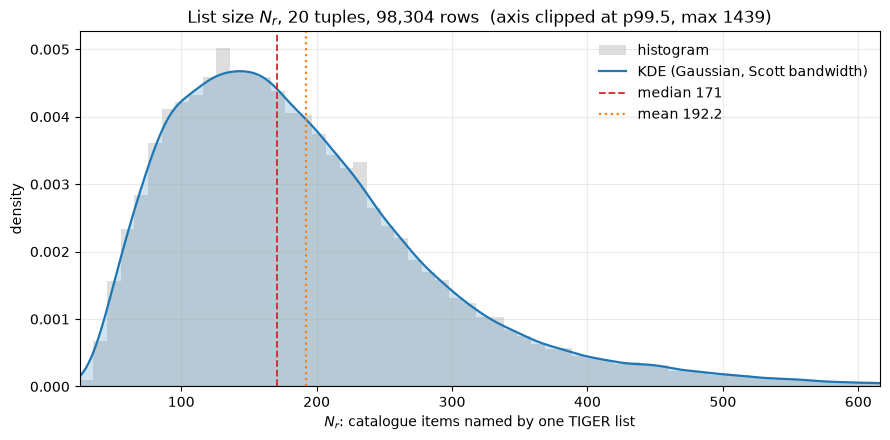

In [9]:
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

kde  = gaussian_kde(n_r)                        # Scott bandwidth
grid = np.linspace(n_r.min(), n_r.max(), 600)
dens = kde(grid)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(n_r, bins=140, density=True, color='0.75', alpha=0.5, label='histogram')
ax.fill_between(grid, dens, color='tab:blue', alpha=0.20)
ax.plot(grid, dens, color='tab:blue', lw=1.6, label='KDE (Gaussian, Scott bandwidth)')
ax.axvline(np.median(n_r), color='tab:red',    ls='--', lw=1.3,
           label=f'median {np.median(n_r):.0f}')
ax.axvline(n_r.mean(),     color='tab:orange', ls=':',  lw=1.6,
           label=f'mean {n_r.mean():.1f}')
ax.set_xlim(n_r.min(), np.percentile(n_r, 99.5))
ax.set_xlabel('$N_r$: catalogue items named by one TIGER list')
ax.set_ylabel('density')
ax.set_title(f'List size $N_r$, 20 tuples, {n_r.size:,} rows  '
             f'(axis clipped at p99.5, max {n_r.max()})')
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
